In [1]:
import pandas as pd

In [2]:
df=pd.read_csv('polynomial_regression_practice-2.csv')

In [3]:
df.head()

,Advertising_Spend,Sales
0,8.12,72.20
1,19.06,288.20
2,14.91,190.88
3,12.37,114.54
4,3.96,25.46


In [4]:
import seaborn as sns

<Axes: xlabel='Advertising_Spend', ylabel='Sales'>

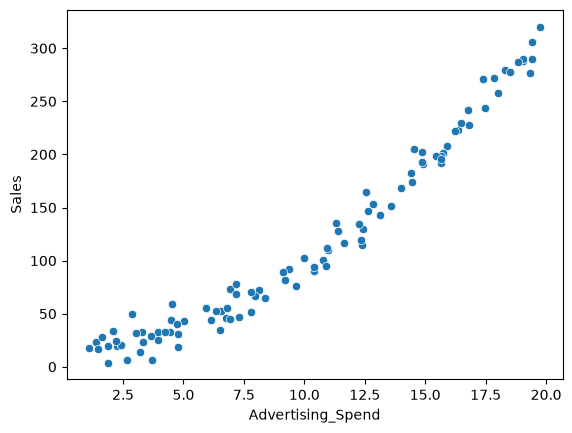

In [5]:
sns.scatterplot(data=df,x='Advertising_Spend',y='Sales')

In [7]:
corr=df.corr(numeric_only=True)
df.corr(numeric_only=True)

,Advertising_Spend,Sales
Advertising_Spend,1.00000,0.96953
Sales,0.96953,1.00000


<Axes: >

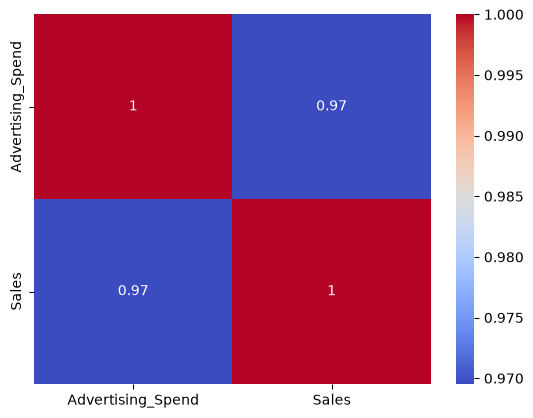

In [8]:
sns.heatmap(corr,annot=True,cmap='coolwarm')

In [9]:
df.head()

,Advertising_Spend,Sales
0,8.12,72.20
1,19.06,288.20
2,14.91,190.88
3,12.37,114.54
4,3.96,25.46


In [11]:
X=df.drop(columns='Sales')
X

,Advertising_Spend
0,8.12
1,19.06
2,14.91
3,12.37
4,3.96
...,...
95,10.38
96,10.93
97,9.12
98,1.48


In [13]:
y=df['Sales']
y

0      72.20
1     288.20
2     190.88
3     114.54
4      25.46
       ...  
95     94.19
96    112.05
97     88.96
98     16.44
99     31.60
Name: Sales, Length: 100, dtype: float64

<Axes: xlabel='Sales'>

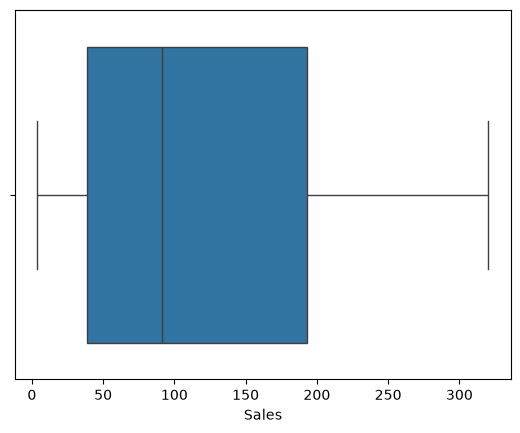

In [14]:
sns.boxplot(data=df,x='Sales')

<Axes: xlabel='Advertising_Spend'>

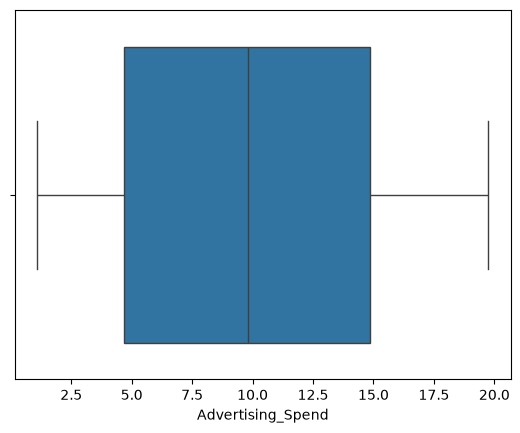

In [15]:
sns.boxplot(data=df,x='Advertising_Spend')

#### Since there is no outliers, therefore We can use Standard Scaler

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import PolynomialFeatures

In [22]:
pipeline=Pipeline(
    steps=[
        ('scaling',StandardScaler()),
        ('poly',PolynomialFeatures(degree=2)),
        ('model',LinearRegression())
    ]
)

In [24]:
from sklearn.model_selection import train_test_split
X_train,X_test,y_train,y_test=train_test_split(
    X,y,test_size=0.2,random_state=42
)

In [25]:
pipeline.fit(X_train,y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('scaling', ...), ('poly', ...), ...]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](1,)",['Advertising_Spend']
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,1
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
Name,Type,Value


In [27]:
from sklearn.metrics import r2_score,mean_absolute_error,root_mean_squared_error

In [30]:
# Train
y_train_pred=pipeline.predict(X_train)
print('r2_score : ',r2_score(y_train,y_train_pred))
print('MAE :', mean_absolute_error(y_train,y_train_pred))
print('RMSE :',root_mean_squared_error(y_train,y_train_pred))

r2_score :  0.9852601211221189
MAE : 8.440854450490233
RMSE : 10.831482379206301


In [31]:
# Train
y_test_pred=pipeline.predict(X_test)
print('r2_score : ',r2_score(y_test,y_test_pred))
print('MAE : ',mean_absolute_error(y_test,y_test_pred))
print('RMSE :',root_mean_squared_error(y_test,y_test_pred))

r2_score :  0.9894576108133466
MAE :  6.935362750181748
RMSE : 9.568443190775689
